# 01: Data collection, cleaning and EDA


In [2]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

RAW = Path("data/raw")
PROC = Path("data/processed")
FIG = Path("figures")
PROC.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

TENORS = ["3M", "1Y", "2Y", "5Y", "10Y", "15Y", "30Y"]
TENOR_YEARS = {"3M": 0.25, "1Y": 1, "2Y": 2, "5Y": 5, "10Y": 10, "15Y": 15, "30Y": 30}
START = "2012-01-01"

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

def savefig(name):
    plt.savefig(FIG / f"{name}.png", bbox_inches="tight")

## 1. load CSVs

In [3]:
def load_investing_csv(path):
    """investing.com export -> Series of daily closing yields (%), indexed by date."""
    df = pd.read_csv(path, thousands=",")
    df["Date"] = pd.to_datetime(df["Date"], format="%m/%d/%Y")
    return df.set_index("Date").sort_index()["Price"].astype(float)

raw = pd.DataFrame({t: load_investing_csv(RAW / f"IN_{t}.csv") for t in TENORS})
print(raw.shape)
print("Missing values per tenor:")
print(raw.isna().sum())
raw.describe().T

(3770, 7)
Missing values per tenor:
3M     22
1Y     61
2Y     60
5Y     61
10Y    55
15Y    61
30Y    54
dtype: int64


,count,mean,std,min,25%,50%,75%,max
3M,3748.0,6.609735,4.562357,2.700,5.40000,6.480,7.45000,98.667
1Y,3709.0,6.599419,1.390257,3.313,5.76900,6.741,7.56600,10.666
2Y,3710.0,6.739261,1.195460,3.861,6.00925,6.859,7.70375,9.862
5Y,3709.0,7.106661,0.949963,4.840,6.45000,7.087,7.86100,9.707
10Y,3715.0,7.245894,0.780290,5.760,6.64950,7.198,7.79650,9.228
15Y,3709.0,7.548801,0.723351,6.244,6.99600,7.416,8.07400,9.617
30Y,3716.0,7.633323,0.676613,6.393,7.12000,7.466,8.05700,9.577


## 2. Clean - 3M rows, dates and outlier patterns

In [4]:
bad = raw["3M"] > 20
print(raw.loc[bad, "3M"])
print("Converted",
      ((100 / raw.loc[bad, "3M"] - 1) * 365 / 91 * 100).round(2).tolist())
bad_dates = raw.index[bad]
raw = raw.drop(bad_dates)

Date
2025-05-06    98.642
2025-05-07    98.573
2025-05-08    98.629
2025-05-12    98.649
2025-05-13    98.667
2025-05-14    98.576
2025-05-15    98.634
2025-05-16    98.634
Name: 3M, dtype: float64
Converted [5.52, 5.81, 5.58, 5.49, 5.42, 5.79, 5.55, 5.55]


In [5]:
print("Rows by weekday (0=Mon):", raw.index.dayofweek.value_counts().sort_index().to_dict())

yields = raw[(raw.index.dayofweek < 5) & raw["10Y"].notna()]
yields = yields.ffill(limit=3).dropna()
yields = yields[yields.index >= START]
print(yields.shape, yields.index.min().date(), "->", yields.index.max().date())

Rows by weekday (0=Mon): {0: 721, 1: 732, 2: 733, 3: 734, 4: 720, 5: 119, 6: 3}
(3628, 7) 2012-01-12 -> 2026-11-11


In [6]:
def hampel_flags(s, window=11, min_move=0.40, n_mad=5):
    med = s.rolling(window, center=True, min_periods=3).median()
    dev = (s - med).abs()
    mad = dev.rolling(window, center=True, min_periods=3).median()
    return (dev > min_move) & (dev > n_mad * 1.4826 * mad)

flags = pd.DataFrame({t: hampel_flags(yields[t]) for t in TENORS})
for t in TENORS:
    for d in yields.index[flags[t]]:
        print(f"{t:>4}  {d.date()}  {yields.at[d, t]:.3f}")

  3M  2013-07-16  9.500
  3M  2020-05-22  2.700
  1Y  2012-05-11  8.822
  1Y  2013-09-09  9.274
  1Y  2022-04-28  4.639
  2Y  2022-05-09  6.313
  2Y  2022-05-12  5.859


3. final ds as processed

In [9]:
data = yields.copy()
assert len(data) > 1000, f"{len(data)} rows" #lot of incomplete sets during dwlnds
data.to_csv(PROC / "dataset.csv")
print(data.shape, data.index.min().date(), "->", data.index.max().date())
data.tail()

(3628, 7) 2012-01-12 -> 2026-11-11


,3M,1Y,2Y,5Y,10Y,15Y,30Y
Date,,,,,,,
2026-11-04,5.88,6.511,7.033,7.061,7.192,7.385,7.664
2026-11-05,5.79,6.517,7.028,7.015,7.169,7.348,7.618
2026-11-06,5.75,6.451,6.870,6.981,7.195,7.372,7.673
2026-11-09,5.70,6.449,6.801,6.956,7.156,7.332,7.730
2026-11-11,5.70,6.420,6.799,6.997,7.210,7.374,7.694


# EDA

4. statistics on full set

In [7]:
summary = data[TENORS].describe().T
summary["skew"] = data[TENORS].skew()
summary.round(3)

,count,mean,std,min,25%,50%,75%,max,skew
3M,3628.0,6.371,1.643,2.700,5.368,6.460,7.380,11.750,-0.152
1Y,3628.0,6.572,1.389,3.313,5.747,6.724,7.463,10.666,-0.414
2Y,3628.0,6.717,1.195,3.861,5.990,6.843,7.646,9.862,-0.439
5Y,3628.0,7.088,0.946,4.840,6.435,7.075,7.822,9.707,-0.051
10Y,3628.0,7.231,0.775,5.760,6.637,7.185,7.780,9.228,0.279
15Y,3628.0,7.534,0.718,6.244,6.989,7.406,8.048,9.617,0.537
30Y,3628.0,7.618,0.670,6.393,7.112,7.456,8.035,9.577,0.712


## 5. yields over time

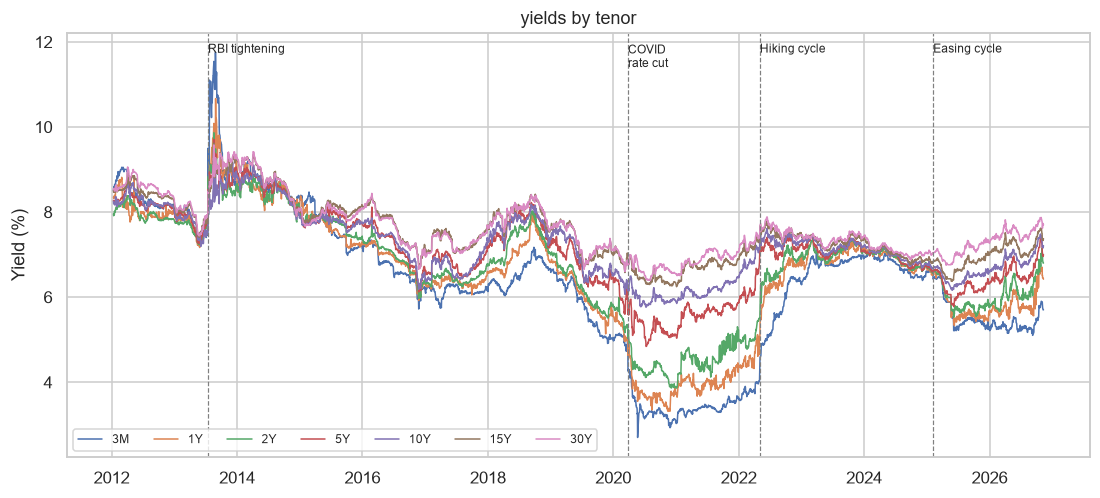

In [10]:
events = {"2013-07-16": "RBI tightening",
          "2020-03-27": "COVID\nrate cut",
          "2022-05-04": "Hiking cycle",
          "2025-02-07": "Easing cycle"}

fig, ax = plt.subplots(figsize=(12, 5))
for t in TENORS:
    ax.plot(data.index, data[t], lw=1, label=t)
for d, label in events.items():
    ax.axvline(pd.Timestamp(d), color="grey", ls="--", lw=0.8)
    ax.text(pd.Timestamp(d), ax.get_ylim()[1] * 0.98, label, fontsize=8, va="top")
ax.set_ylabel("Yield (%)")
ax.set_title("yields by tenor")
ax.legend(ncol=7, loc="lower left", fontsize=8)
savefig("01_yields_over_time")
plt.show()

## 6. yield curve on selected dates

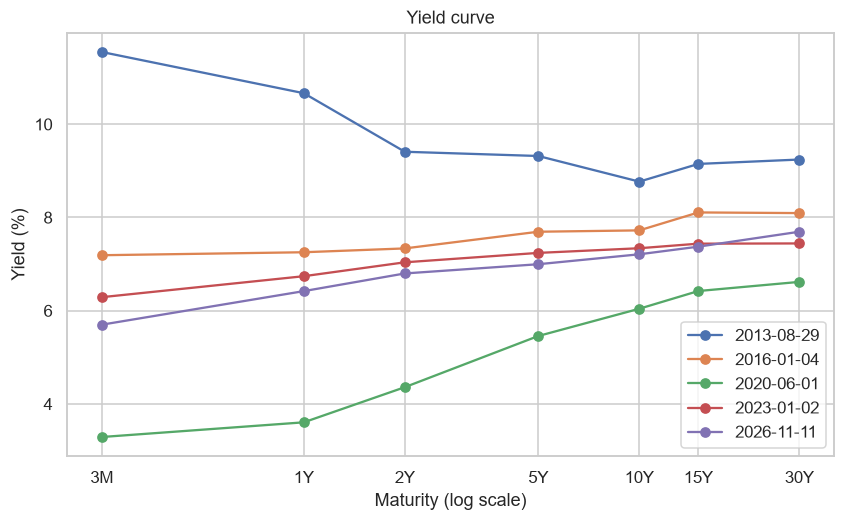

In [11]:
snap_dates = ["2013-08-29", "2016-01-04", "2020-06-01", "2023-01-02", str(data.index.max().date())]
x = [TENOR_YEARS[t] for t in TENORS]

fig, ax = plt.subplots(figsize=(9, 5))
for d in snap_dates:
    row = data.loc[data.index.asof(pd.Timestamp(d)), TENORS]
    ax.plot(x, row.values, marker="o", label=str(row.name.date()))
ax.set_xscale("log")
ax.set_xticks(x)
ax.set_xticklabels(TENORS)
ax.set_xlabel("Maturity (log scale)")
ax.set_ylabel("Yield (%)")
ax.set_title("Yield curve")
ax.legend()
savefig("02_curve_snapshots")
plt.show()

## 7. 10Y vs 3M curve

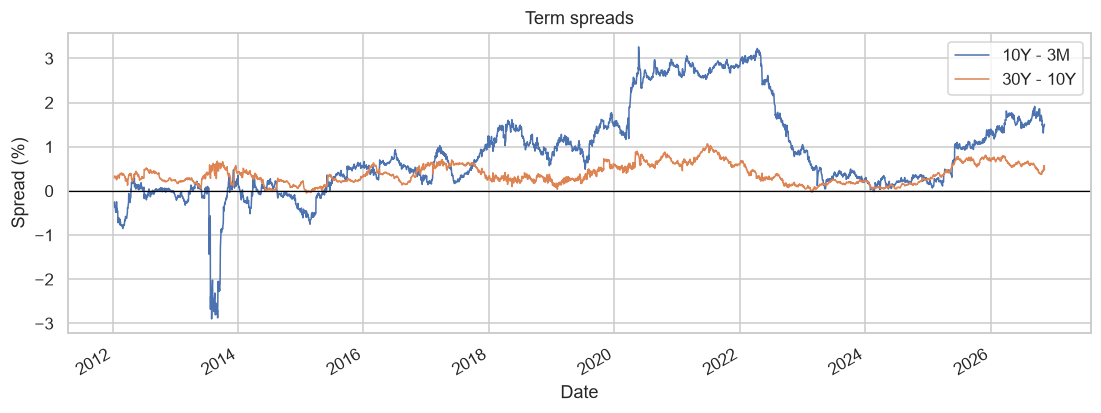

Days with inverted 10Y-3M: 528


In [12]:
spreads = pd.DataFrame({
    "10Y - 3M": data["10Y"] - data["3M"],
    "30Y - 10Y": data["30Y"] - data["10Y"],
})
ax = spreads.plot(figsize=(12, 4), lw=1)
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("Spread (%)")
ax.set_title("Term spreads")
savefig("03_term_spreads")
plt.show()


print("Days with inverted 10Y-3M:", int((spreads["10Y - 3M"] < 0).sum()))

## 8. levels vs daily changes

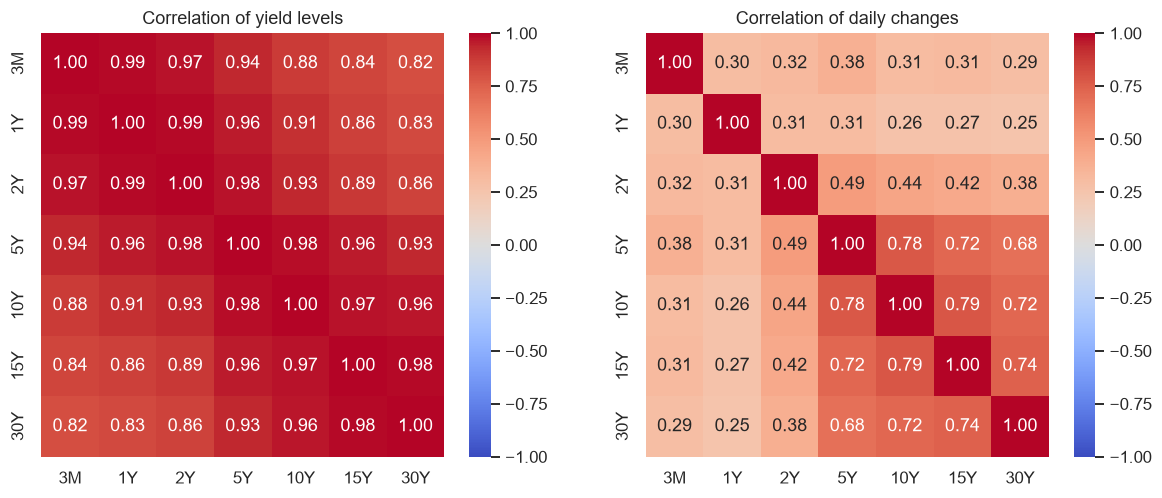

In [14]:
levels = data[TENORS]
changes = data[TENORS].diff().dropna() * 100      # bps measure because levels already shows num value

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(levels.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Correlation of yield levels")
sns.heatmap(changes.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Correlation of daily changes")
savefig("04_correlations")
plt.show()

## 9. daily changes

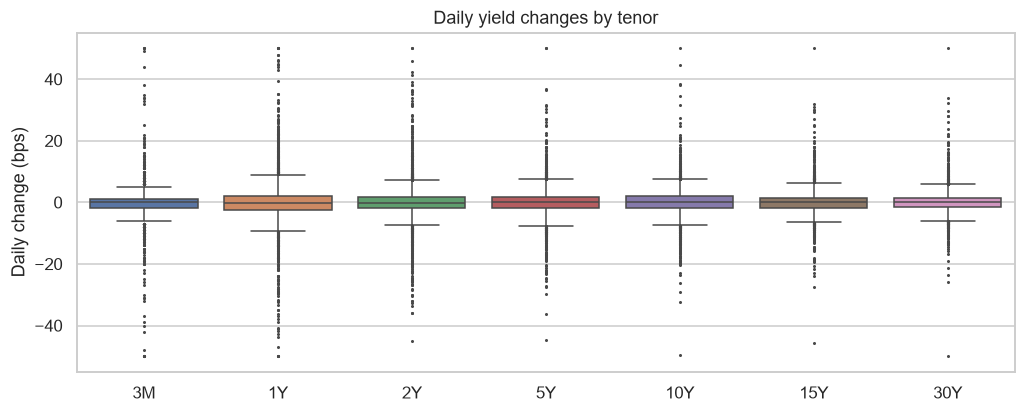

In [16]:
fig, ax = plt.subplots(figsize=(11, 4))
sns.boxplot(data=changes.clip(-50, 50), ax=ax, fliersize=1)
ax.set_ylabel("Daily change (bps)")
ax.set_title("Daily yield changes by tenor")
savefig("05_daily_change_boxplot")
plt.show()

## 10. Persistence: are yields predictable from yesterday? what sort of distribution do these features follow?

ADF test convention

,ADF p-value (level),ADF p-value (daily change)
3M,0.2761,0.0
1Y,0.2917,0.0
2Y,0.3646,0.0
5Y,0.2798,0.0
10Y,0.2757,0.0
15Y,0.2088,0.0
30Y,0.1589,0.0


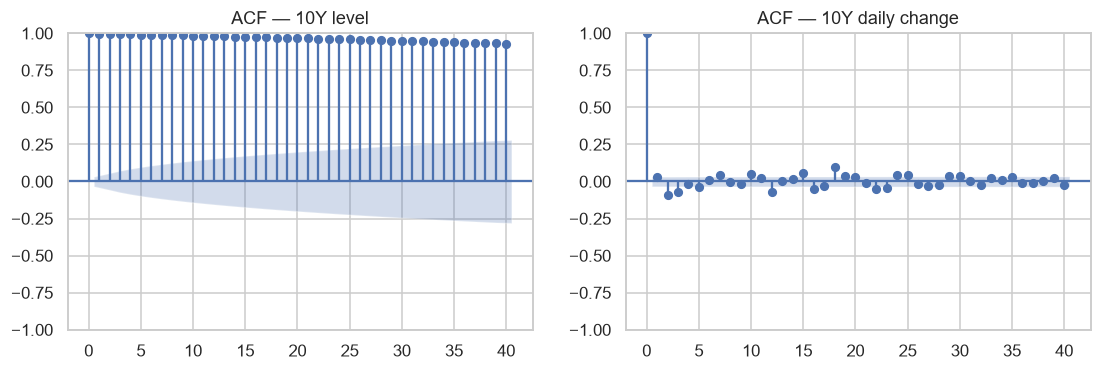

In [17]:
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf

adf = pd.DataFrame({
    "ADF p-value (level)": [adfuller(levels[t])[1] for t in TENORS],
    "ADF p-value (daily change)": [adfuller(changes[t])[1] for t in TENORS],
}, index=TENORS)
display(adf.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
plot_acf(levels["10Y"], lags=40, ax=axes[0], title="ACF — 10Y level")
plot_acf(changes["10Y"], lags=40, ax=axes[1], title="ACF — 10Y daily change")
savefig("06_acf_10y")
plt.show()

## 11. PCA: level, slope and curvature

bond features of importance always end up being 1.level, 2.slope and 3.curvature

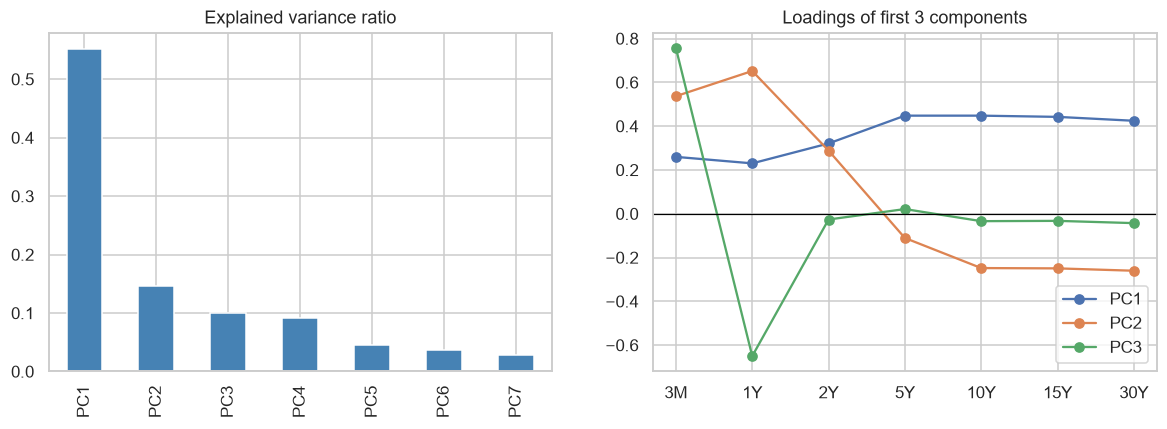

In [18]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

Z = StandardScaler().fit_transform(changes)
pca = PCA().fit(Z)
explained = pd.Series(pca.explained_variance_ratio_, index=[f"PC{i+1}" for i in range(len(TENORS))])
# print((explained.cumsum() * 100).round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
explained.plot.bar(ax=axes[0], color="steelblue")
axes[0].set_title("Explained variance ratio")
for i, name in enumerate(["PC1", "PC2", "PC3"]):
    axes[1].plot(TENORS, pca.components_[i], marker="o", label=name)
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_title("Loadings of first 3 components")
axes[1].legend()
savefig("07_pca")
plt.show()

## 12. Feature correlation

from yield curve:

| feature | meaning | convention |
|---|---|---|
| `d1`, `d5`, `d20` | change over the last 1 / 5 / 20 days (bps) | momentum or reversal |
| `dev20` | yield minus its 20-day average (bps) | mean reversion |
| `vol20` | std. dev. of daily changes over 20 days (bps) | how turbulent the market is |
| `10Y−3M`, `30Y−10Y` | term spreads (pp) | slope of the curve |
| `curv` | 2×5Y − 2Y − 10Y (pp) | curvature |

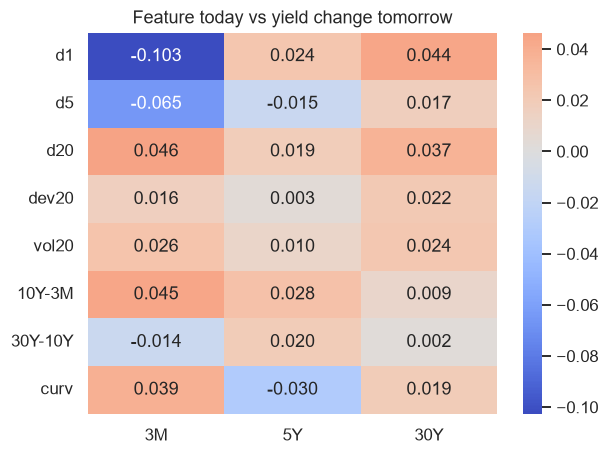

In [19]:
TARGETS = ["3M", "5Y", "30Y"]
lead = {}
for t in TARGETS:
    y = data[t]
    d1 = y.diff() * 100
    signals = pd.DataFrame({
        "d1": d1,
        "d5": y.diff(5) * 100,
        "d20": y.diff(20) * 100,
        "dev20": (y - y.rolling(20).mean()) * 100,
        "vol20": d1.rolling(20).std(),
        "10Y-3M": data["10Y"] - data["3M"],
        "30Y-10Y": data["30Y"] - data["10Y"],
        "curv": 2 * data["5Y"] - data["2Y"] - data["10Y"],
    })
    next_change = y.diff().shift(-1) * 100
    lead[t] = signals.corrwith(next_change)

lead = pd.DataFrame(lead)
plt.figure(figsize=(6, 4.5))
sns.heatmap(lead, annot=True, fmt=".3f", cmap="coolwarm", center=0)
plt.title("Feature today vs yield change tomorrow")
savefig("08_lead_correlations")
plt.show()